In [1]:
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input, decode_predictions
from tensorflow.keras.preprocessing import image

import numpy as np

In [3]:
model = ResNet50(weights = 'imagenet') 

# weights = imagenet means, keep weights as those fixed during imagenet commpetation

102967424/102967424 [==============================] - 101s 1us/step


In [4]:
model.summary()

Model: "resnet50"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 224, 224, 3)]        0         []                            
                                                                                                  
 conv1_pad (ZeroPadding2D)   (None, 230, 230, 3)          0         ['input_1[0][0]']             
                                                                                                  
 conv1_conv (Conv2D)         (None, 112, 112, 64)         9472      ['conv1_pad[0][0]']           
                                                                                                  
 conv1_bn (BatchNormalizati  (None, 112, 112, 64)         256       ['conv1_conv[0][0]']          
 on)                                                                                       

In [33]:
import cv2
import matplotlib.pyplot as plt

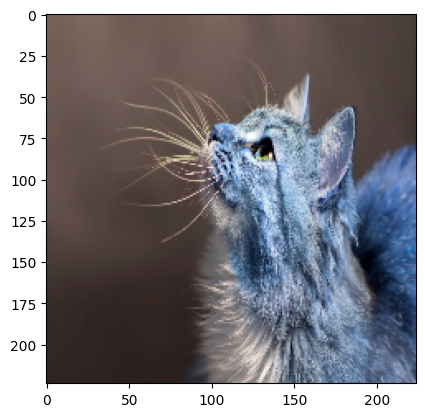

In [53]:
img_path = r'D:\Nikss\Self Pracitce\Deep learning\02 Convolution Neural Network\00 Images for prediction/Cat.webp'

image = cv2.imread(img_path)    # Reading image
image = cv2.resize(image, (224,224))    # Resizing bcz ResNet Accepts (224,224)

plt.imshow(image)

In [54]:
image.shape

(224, 224, 3)

In [55]:
# Converting shape to batch or say 4d bcz model expects batch as input

image = image.reshape((1,224,224,3))

image.shape

# We can also use np.expand_dims(image, axis = 0)    This is better to use

(1, 224, 224, 3)

In [56]:
# Preprocessing image

image = preprocess_input(image)

# preprocess_input() fixes the credentials acceptable by ResNet model

In [57]:
# making prediction

pred = model.predict(image)

1/1 [==============================] - 1s 1s/step


In [71]:
pred

array([[1.59182662e-07, 5.24871382e-07, 3.63313211e-06, 7.74038472e-06,
        7.75145338e-07, 1.75510604e-06, 5.36238758e-07, 9.27262681e-06,
        1.46104387e-04, 4.14463691e-03, 1.99696228e-06, 4.49676861e-07,
        2.32961247e-06, 1.79585622e-05, 5.03215742e-05, 3.56534729e-05,
        1.03340490e-05, 5.37947536e-01, 4.63287084e-04, 2.93761732e-05,
        2.28028839e-05, 8.53754773e-06, 2.80966583e-06, 9.19804152e-05,
        4.80478047e-04, 5.84772920e-07, 1.42611020e-06, 2.57579103e-07,
        3.09898923e-07, 1.14056400e-06, 5.93722348e-07, 6.30167676e-07,
        5.95435949e-07, 4.54882468e-07, 3.01190039e-06, 8.45394595e-07,
        2.62129788e-06, 6.26368646e-08, 2.59418670e-07, 5.49375591e-06,
        1.92313124e-07, 2.61133982e-06, 1.58537034e-04, 1.47243278e-04,
        1.60859270e-06, 1.90806600e-06, 2.69616692e-07, 9.91086608e-07,
        3.21626044e-06, 2.31435297e-06, 2.16804006e-06, 5.08775429e-06,
        8.97151722e-07, 1.42354821e-07, 8.55510280e-06, 5.291652

In [74]:
decode_predictions(pred, top = 3)

[[('n01580077', 'jay', 0.53794754),
  ('n02123159', 'tiger_cat', 0.06317175),
  ('n02128757', 'snow_leopard', 0.0471871)]]

In [75]:
# Predicting laptop

laptop = r'D:\Nikss\Self Pracitce\Deep learning\02 Convolution Neural Network\00 Images for prediction/laptop.webp'

laptop = cv2.imread(laptop)

laptop = cv2.resize(laptop, (224,224))

laptop = np.expand_dims(laptop, axis = 0)

In [76]:
laptop.shape

(1, 224, 224, 3)

In [77]:
pred_laptop = model.predict(laptop)

len(pred_laptop[0])    # 1000 bcz predict() gives probabilities of all 1000 images

1/1 [==============================] - 1s 1s/step


1000

In [79]:
decode_predictions(pred_laptop, top = 3)

[[('n03832673', 'notebook', 0.5706192),
  ('n03642806', 'laptop', 0.42762437),
  ('n03180011', 'desktop_computer', 0.0010770141)]]

In [97]:
# Predicting Pizza

pizza = r'D:\Nikss\Self Pracitce\Deep learning\02 Convolution Neural Network\00 Images for prediction/pizza.jpg'

pizza = cv2.imread(pizza)

pizza = cv2.resize(pizza, (224,224))

pizza = np.expand_dims(pizza, axis = 0)    # expand_dims() adds one more dimension to an array

pizza.shape

(1, 224, 224, 3)

In [98]:
pred_pizza = model.predict(pizza)

1/1 [==============================] - 0s 177ms/step


In [99]:
decode_predictions(pred_pizza, top = 3)

[[('n07873807', 'pizza', 0.6354384),
  ('n07875152', 'potpie', 0.27631775),
  ('n07717410', 'acorn_squash', 0.008345752)]]

In [101]:
# Predicting a boy

boy = r'D:\Nikss\Self Pracitce\Deep learning\02 Convolution Neural Network\00 Images for prediction/boy.jpg'

boy = cv2.imread(boy)

boy = cv2.resize(boy, (224,224))

boy = np.expand_dims(boy, axis = 0)    # expand_dims() adds one more dimension to an array

pizza.shape

(1, 224, 224, 3)

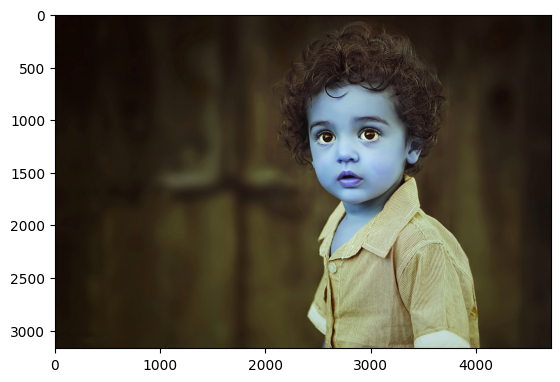

In [104]:
plt.imshow(cv2.imread(r'D:\Nikss\Self Pracitce\Deep learning\02 Convolution Neural Network\00 Images for prediction/boy.jpg'))

In [108]:
pred_boy = model.predict(boy)

1/1 [==============================] - 0s 137ms/step


In [109]:
decode_predictions(pred_boy, top = 3)

[[('n02963159', 'cardigan', 0.26116338),
  ('n03594734', 'jean', 0.20037101),
  ('n03710637', 'maillot', 0.07690868)]]

In [111]:
# Predicting a fridge

fridge = r'D:\Nikss\Self Pracitce\Deep learning\02 Convolution Neural Network\00 Images for prediction/fridge.jpeg'

fridge = cv2.imread(fridge)

fridge = cv2.resize(fridge, (224,224))

fridge = np.expand_dims(fridge, axis = 0)    # expand_dims() adds one more dimension to an array

fridge.shape

(1, 224, 224, 3)

In [113]:
pred_fridge = model.predict(fridge)
decode_predictions(pred_fridge, top = 3)

1/1 [==============================] - 0s 175ms/step


[[('n06359193', 'web_site', 0.5890611),
  ('n04070727', 'refrigerator', 0.30954602),
  ('n07565083', 'menu', 0.037761886)]]

In [114]:
# Predicting specs

fridge = r'D:\Nikss\Self Pracitce\Deep learning\02 Convolution Neural Network\00 Images for prediction/specs.webp'

fridge = cv2.imread(fridge)

fridge = cv2.resize(fridge, (224,224))

fridge = np.expand_dims(fridge, axis = 0)    # expand_dims() adds one more dimension to an array

fridge.shape

(1, 224, 224, 3)

In [115]:
pred_specs = model.predict(fridge)
decode_predictions(pred_specs, top = 3)

1/1 [==============================] - 0s 151ms/step


[[('n03532672', 'hook', 0.09436847),
  ('n04356056', 'sunglasses', 0.0730058),
  ('n03759954', 'microphone', 0.06516671)]]

# Next session: Day - 52 What does CNN see  (colab `nikunjbos26@gmail.com`)
# Day 53 - Transfer learning (colab `nikunjbos26@gmail.com`)